<a href="https://colab.research.google.com/github/muhammadyusuf-pro/Machine-Learning-Course/blob/main/XGBoosting%20Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from xgboost import XGBClassifier

# Iris datasetini yuklaymiz
iris = load_iris()
X = iris.data
y = iris.target

# Train test split qildik
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y)
print("Train score:", X_train.shape)
print("Test score:", X_test.shape)

# XGBoost modelini yasaymiz va o'qitamiz
model = XGBClassifier(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("Classification report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

# XGBClassifier modeli Iris datasetida 93.3% accuracy ko’rsatdi.
# Setosa sinfi eng yaxshi ajratildi precision va recall = 1.00, chunki u boshqa gullardan aniq farq qiladi.

Train score: (120, 4)
Test score: (30, 4)
Accuracy: 0.9333333333333333
Confusion matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]
Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [3]:
from sklearn.model_selection import GridSearchCV
base_model = XGBClassifier(random_state=42)
base_model.fit(X_train, y_train)
base_pred = base_model.predict(X_test)
base_acc = accuracy_score(y_test, base_pred)
print("Boshlang'ich model accuracy:", base_acc)


param_grid = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [2, 3, 5],
    "subsample": [0.8, 1.0]
}

# GridSearchCV qildik
grid = GridSearchCV(
    estimator=XGBClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
grid.fit(X_train, y_train)

# Eng yaxshi parametrlar
print("Eng yaxshi parametrlar:", grid.best_params_)
print("Cross-validation accuracy:", grid.best_score_)

# Eng yaxshi modelni test to'plamida baholaymiz
best_model = grid.best_estimator_
best_pred = best_model.predict(X_test)
best_acc = accuracy_score(y_test, best_pred)
print("Tuning qilingan model accuracy:", best_acc)
print(classification_report(y_test, best_pred, target_names=iris.target_names))

# Taqqoslash
print("Boshlang'ich model:", round(base_acc, 4))
print("Tuning qilingan   :", round(best_acc, 4))

# Ha, GridSearchCV test natijasini yaxshiladi: accuracy 93.3% dan 96.7% ga oshdi.
# Eng yaxshi parametrlar: learning_rate=0.01, max_depth=3, n_estimators=200, subsample=0.8.

Boshlang'ich model accuracy: 0.9333333333333333
Eng yaxshi parametrlar: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}
Cross-validation accuracy: 0.9583333333333333
Tuning qilingan model accuracy: 0.9666666666666667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Boshlang'ich model: 0.9333
Tuning qilingan   : 0.9667


 max_depth  train_accuracy  test_accuracy    gap
         1             1.0         0.9000 0.1000
         2             1.0         0.9333 0.0667
         3             1.0         0.9333 0.0667
         5             1.0         0.9333 0.0667
         8             1.0         0.9333 0.0667
        12             1.0         0.9333 0.0667


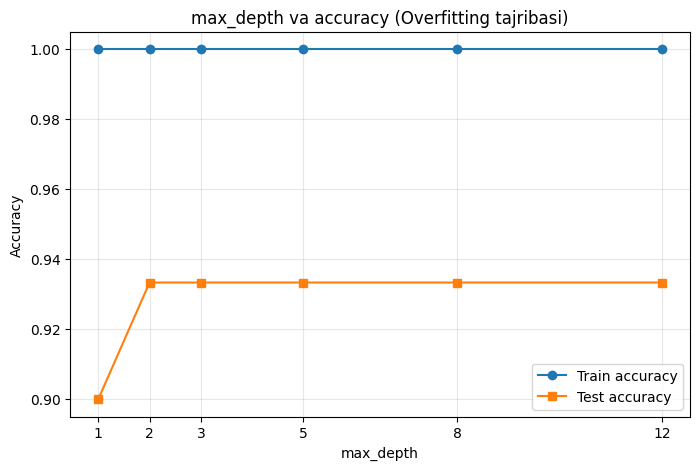

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

depths = [1, 2, 3, 5, 8, 12]
results = []

for d in depths:
    model = XGBClassifier(max_depth=d, random_state=42)
    model.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))
    gap = train_acc - test_acc

    results.append({
        "max_depth": d,
        "train_accuracy": round(train_acc, 4),
        "test_accuracy": round(test_acc, 4),
        "gap": round(gap, 4)
    })

df = pd.DataFrame(results)
print(df.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.plot(df["max_depth"], df["train_accuracy"], marker="o", label="Train accuracy")
plt.plot(df["max_depth"], df["test_accuracy"], marker="s", label="Test accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("max_depth va accuracy (Overfitting tajribasi)")
plt.xticks(depths)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# BU topshiriqda train accuracy barcha chuqurliklarda 1.00 bo’ldi, ya’ni model train ma’lumotlarini mukammal yodlab oldi.
# Test accuracy esa 0.90 (max_depth=1) dan 0.9333 (max_depth≥2) gacha o’zgardi va undan keyin o’zgarmadi.

In [8]:
# Sinab ko'riladigan 4 ta kombinatsiya
combos = [(1.0, 1.0), (0.8, 1.0), (1.0, 0.8), (0.8, 0.8)]

results = []

# Har bir kombinatsiya uchun model yasaymiz
for sub, col in combos:
    model = XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        subsample=sub,
        colsample_bytree=col,
        random_state=42
    )
    model.fit(X_train, y_train)

    # Train va test accuracy
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))

    results.append({
        "subsample": sub,
        "colsample_bytree": col,
        "train_accuracy": round(train_acc, 4),
        "test_accuracy": round(test_acc, 4),
        "gap": round(train_acc - test_acc, 4)
    })

# Natijalarni bitta jadvalda ko'rsatamiz
df = pd.DataFrame(results)
print(df.to_string(index=False))

# bu topshiriqda eng yaxshi kombinatsiya subsample=0.8, colsample_bytree=0.8 bo’ldi
# u test natijasini yaxshiladi va overfitting farqini kamaytirdi.

 subsample  colsample_bytree  train_accuracy  test_accuracy    gap
       1.0               1.0             1.0         0.9333 0.0667
       0.8               1.0             1.0         0.9333 0.0667
       1.0               0.8             1.0         0.9333 0.0667
       0.8               0.8             1.0         0.9667 0.0333


In [11]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

# Sun'iy dataset yaratamiz
np.random.seed(42)
n = 300

area_m2 = np.random.randint(40, 200, n)
rooms = np.random.randint(1, 6, n)
age_years = np.random.randint(0, 50, n)

# Narx + tasodifiy shovqin
noise = np.random.normal(0, 5000, n)
price = 1000 * area_m2 + 5000 * rooms - 800 * age_years + 20000 + noise

df = pd.DataFrame({
    "area_m2": area_m2,
    "rooms": rooms,
    "age_years": age_years,
    "price": price.round(2)
})
print(df.head())

# Feature va targetni ajratamiz
X = df[["area_m2", "rooms", "age_years"]]
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# XGBRegressor modelini o'qitamiz
model = XGBRegressor(n_estimators=100, learning_rate=0.1,
                     max_depth=3, random_state=42)
model.fit(X_train, y_train)

# Test natijasini baholaymiz
pred = model.predict(X_test)
mae = mean_absolute_error(y_test, pred)
mse = mean_squared_error(y_test, pred)
rmse = np.sqrt(mse)
print("MAE :", round(mae, 2))
print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))

# 3 ta yangi uy uchun narx bashorat qilamiz
new_houses = pd.DataFrame({
    "area_m2":   [60, 100, 150],
    "rooms":     [2, 3, 4],
    "age_years": [20, 10, 2]
})
new_houses["bashorat_narx"] = model.predict(new_houses).round(0)
print("Yangi uylar:")
print(new_houses)


# learning_rate va n_estimators taqqoslash
pairs = [(0.01, 50), (0.01, 200), (0.1, 50), (0.1, 100), (0.1, 200), (0.3, 100)]
rows = []
for lr, ne in pairs:
    m = XGBRegressor(n_estimators=ne, learning_rate=lr,
                     max_depth=3, random_state=42)
    m.fit(X_train, y_train)
    rows.append({
        "learning_rate": lr,
        "n_estimators": ne,
        "MAE": round(mean_absolute_error(y_test, m.predict(X_test)), 2)
    })
print("MAE ni taqqoslash")
print(pd.DataFrame(rows).to_string(index=False))

# Tajriba natijasiga ko’ra, learning_rate kichik bo’lganda model sekin o’rganadi
# va yetarli natija uchun ko’proq daraxt (n_estimators) kerak bo’ladi:
# learning_rate=0.01 bilan 50 ta daraxtda MAE 29 435 bo’lgan, 200 ta daraxtda 11 992 gacha tushdi,
# learning_rate=0.1 bilan model tez o’rganib, 100 ta daraxtda MAE ≈ 6 636 ga yetdi, daraxtlar sonini 200 ga oshirish natijani deyarli o’zgartirmadi (6 637).

   area_m2  rooms  age_years      price
0      142      1         48  127405.26
1      132      3         13  152062.18
2       54      2         14   69916.14
3      146      1         30  150776.96
4      111      2          0  143504.59
MAE : 6635.6
MSE : 63077661.16
RMSE: 7942.14
Yangi uylar:
   area_m2  rooms  age_years  bashorat_narx
0       60      2         20        75105.0
1      100      3         10       121987.0
2      150      4          2       190744.0
MAE ni taqqoslash
 learning_rate  n_estimators      MAE
          0.01            50 29435.05
          0.01           200 11992.11
          0.10            50  7035.49
          0.10           100  6635.60
          0.10           200  6636.83
          0.30           100  6657.01
